In [13]:
# load and clean
import pandas as pd                                    # pandas: the standard library for tables ("DataFrames")
from pathlib import Path                               # Path: handles file paths cleanly

RAW = Path("../data/raw/stroebl")                      # notebooks/ is one level below the repo root, hence ../
meta = pd.read_csv(RAW / "experiments_meta.csv")       # read the CSV into a DataFrame
meta.columns = meta.columns.str.strip()                # strip stray spaces from column names (fixes " volt_meter")
meta["substudy"] = meta["type"].map({"k": "calendar", "z": "cycle"})   # readable label for k/z
meta.head()                                            # show the first 5 rows (a cell's last line is displayed automatically)

,serial_internal,serial,lab,type,tp,cell,amb_temp_tp,soc_max_tp,dod_tp,c_ch_tp,c_dch_tp,sampling,stage,m_0,scale,R_1khz_0,resistance_meter,U_0,volt_meter,substudy
0,S001,TP_k01_01,SIE,k,1,1,10,0.05,0.0,0.0,0.0,FF,1,68.643,Sartorius BP 310S,13.44,HP 4338B Milliohmmeter,3.5785,Fluke 189,calendar
1,S002,TP_k01_02,SIE,k,1,2,10,0.05,0.0,0.0,0.0,FF,1,68.278,Sartorius BP 310S,12.56,HP 4338B Milliohmmeter,3.5769,Fluke 189,calendar
2,S003,TP_k01_03,SIE,k,1,3,10,0.05,0.0,0.0,0.0,FF,1,68.606,Sartorius BP 310S,12.33,HP 4338B Milliohmmeter,3.5748,Fluke 189,calendar
3,S004,TP_k02_01,SIE,k,2,1,10,0.50,0.0,0.0,0.0,FF,1,68.585,Sartorius BP 310S,12.64,HP 4338B Milliohmmeter,3.5793,Fluke 189,calendar
4,S005,TP_k02_02,SIE,k,2,2,10,0.50,0.0,0.0,0.0,FF,1,68.401,Sartorius BP 310S,12.91,HP 4338B Milliohmmeter,3.5750,Fluke 189,calendar


In [14]:
# reconcile with the paper (279 cells, 71 test points)
print("cells:", len(meta))                                    # one row per cell; the paper says 279
print("unique test points:", meta.groupby(["type", "tp"]).ngroups)   # distinct (type, tp) pairs; the paper says 71
print(meta["sampling"].value_counts())                       # how many cells per design method
print(meta["stage"].value_counts())                          # how many cells per stage

cells: 279
unique test points: 36
sampling
cLH       111
FF         84
pi         60
manual     24
Name: count, dtype: int64
stage
1    141
2    138
Name: count, dtype: int64


In [15]:
table1 = (meta.groupby(["substudy", "stage", "sampling"])     # group by sub-study × stage × design method
              .agg(cells=("serial", "count"),                 # count cells in each group
                   test_points=("tp", "nunique"))             # count distinct test points in each group
              .reset_index())                                 # turn the group labels back into ordinary columns
table1

,substudy,stage,sampling,cells,test_points
0,calendar,1,FF,66,11
1,calendar,2,FF,18,3
2,calendar,2,manual,24,4
3,calendar,2,pi,24,4
4,cycle,1,cLH,75,25
5,cycle,2,cLH,36,12
6,cycle,2,pi,36,12


In [16]:
reps = meta.groupby(["type", "tp"]).size()                    # number of cells at each test point
print(reps.value_counts())                                    # how many test points have 1, 2, 3, … cells; mostly 3 is expected

6     24
12    11
3      1
Name: count, dtype: int64


In [17]:
meta["tp_id"] = (meta["type"] + "_s" + meta["stage"].astype(str)        # e.g. "k_s1_FF_01": sub-study, stage,
                 + "_" + meta["sampling"] + "_" + meta["tp"].astype(str).str.zfill(2))   # design, and tp number (zfill pads 1 → 01)
print("unique test points:", meta["tp_id"].nunique())                   # should now be 71

factors = ["amb_temp_tp", "soc_max_tp", "dod_tp", "c_ch_tp", "c_dch_tp"]   # the stress-factor columns
n_conds = meta.groupby("tp_id")[factors].nunique().max(axis=1)          # for each test point, how many distinct values any factor takes
print("test points with mixed conditions:", (n_conds > 1).sum())        # should be 0: every cell at a test point gets the same treatment
print(meta.groupby("tp_id").size().value_counts())                      # cells per test point: 6 for calendar, 3 for cycle is expected

unique test points: 71
test points with mixed conditions: 0
3    49
6    22
Name: count, dtype: int64


In [18]:
cal = meta[meta["substudy"] == "calendar"]                              # calendar cells only
pd.crosstab([cal["amb_temp_tp"], cal["soc_max_tp"]],                    # rows: each (T, SoC) combination
            [cal["stage"], cal["sampling"]])                            # columns: stage × design; values = number of cells

stage                   1  2           
sampling               FF FF manual  pi
amb_temp_tp soc_max_tp                 
10          0.05        6  0      0   0
            0.20        0  6      0   0
            0.50        6  0      0   0
            0.80        0  6      0   0
            1.00        6  0      0   0
23          0.05        6  0      0   0
            0.20        0  6      0   0
            0.50        6  0      0   0
            0.65        0  0      6   0
            0.80        0  0      0  24
            0.90        0  0      6   0
            1.00        6  0      0   0
45          0.05        6  0      0   0
            0.20        6  0      0   0
            0.50        6  0      0   0
            0.65        0  0      6   0
            0.80        6  0      0   0
            0.90        0  0      6   0
            1.00        6  0      0   0

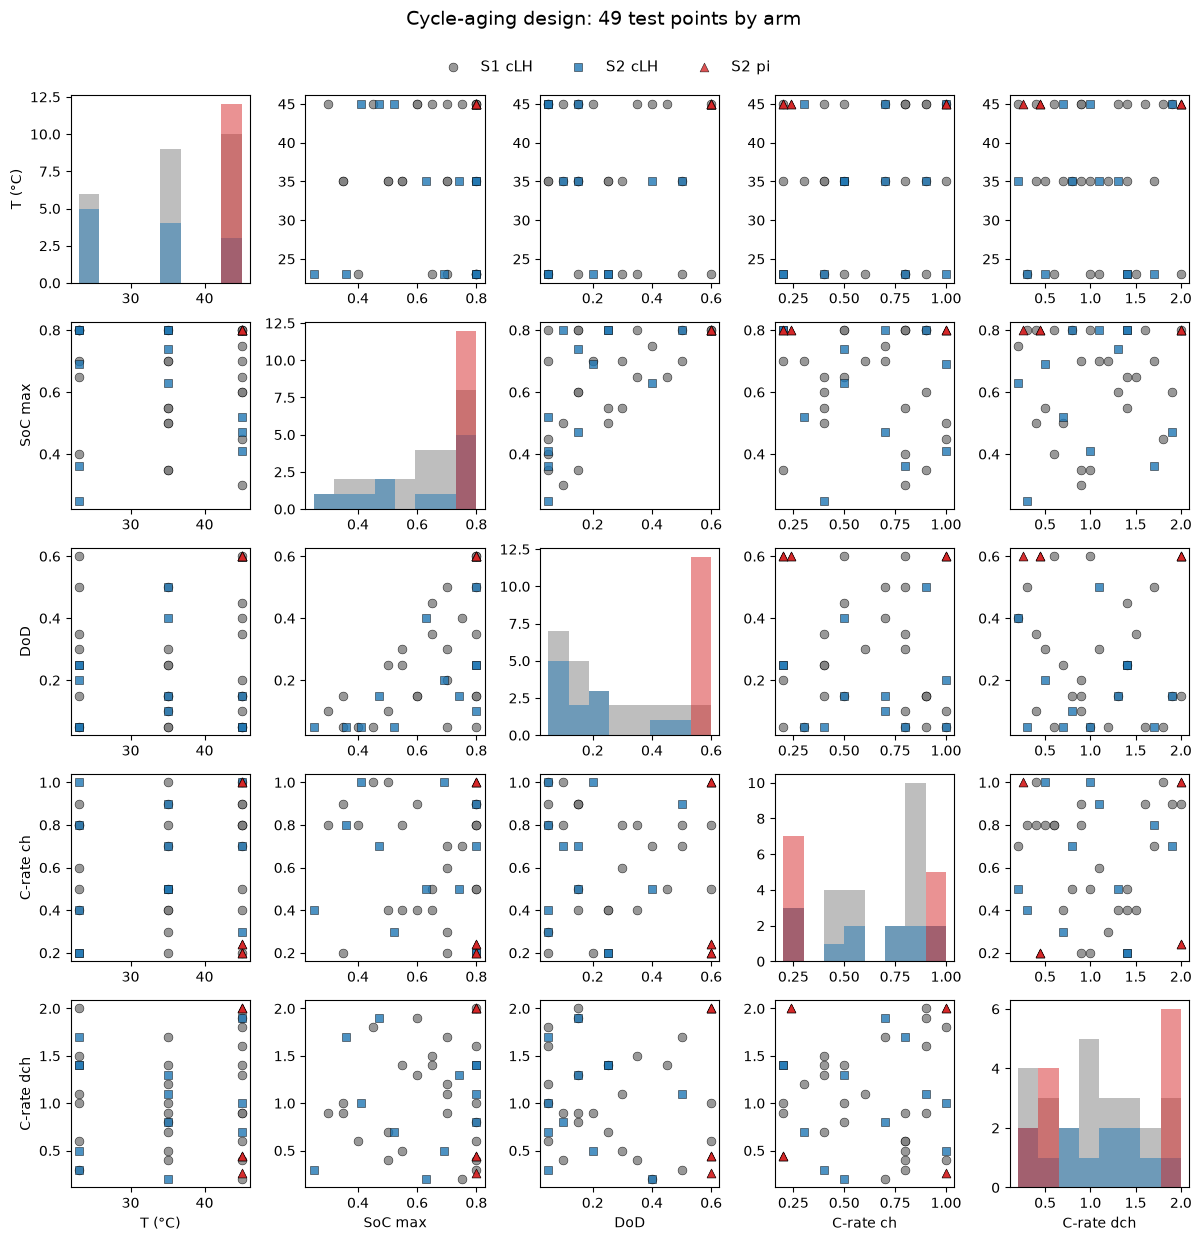

In [19]:
# crosstab for cycle aging
import matplotlib.pyplot as plt                                   # matplotlib: the standard Python plotting library
import itertools                                                  # itertools: tools for looping over combinations
import numpy as np

cyc = meta[meta["substudy"] == "cycle"].copy()                    # cycle cells only (.copy() avoids pandas warnings when adding columns)
cyc["arm"] = "S" + cyc["stage"].astype(str) + " " + cyc["sampling"]   # arm label, e.g. "S1 cLH", "S2 cLH", "S2 pi"
tps = cyc.drop_duplicates("tp_id")                                # one row per test point (all 3 cells share the same factors)

factors = ["amb_temp_tp", "soc_max_tp", "dod_tp", "c_ch_tp", "c_dch_tp"]   # the 5 stress factors
labels  = ["T (°C)", "SoC max", "DoD", "C-rate ch", "C-rate dch"]          # readable axis labels
style = {"S1 cLH": ("tab:gray", "o"),                             # arm → (color, marker): stage-1 pilot in gray circles
         "S2 cLH": ("tab:blue", "s"),                             # S2a control in blue squares
         "S2 pi":  ("tab:red", "^")}                              # S2b OED in red triangles

k = len(factors)                                                  # 5 factors → a 5×5 grid of panels
fig, axes = plt.subplots(k, k, figsize=(12, 12))                  # create the grid; axes[i, j] is one panel

for i, j in itertools.product(range(k), range(k)):                # loop over every (row, column) pair
    ax = axes[i, j]                                               # the current panel
    if i == j:                                                    # diagonal: a factor against itself isn't informative...
        lo, hi = tps[factors[i]].min(), tps[factors[i]].max()      # full range of this factor across all arms
        bins = np.linspace(lo, hi, 9)                              # 8 equal-width bins shared by every arm
        for arm, (c, m) in style.items():
            ax.hist(tps.loc[tps["arm"] == arm, factors[i]], bins=bins, color=c, alpha=0.5)
    else:                                                         # off-diagonal: scatter of factor j (x) vs factor i (y)
        for arm, (c, m) in style.items():
            d = tps[tps["arm"] == arm]                            # this arm's test points
            ax.scatter(d[factors[j]], d[factors[i]], c=c, marker=m,
                       s=40, alpha=0.8, edgecolor="k", lw=0.4, label=arm)   # s = marker size; thin black edges help overlapping dots
    if i == k - 1: ax.set_xlabel(labels[j])                       # x labels only on the bottom row
    if j == 0:     ax.set_ylabel(labels[i])                       # y labels only on the left column

handles, names = axes[0, 1].get_legend_handles_labels()            # take the legend entries from one scatter panel
fig.suptitle("Cycle-aging design: 49 test points by arm", fontsize=14, y=1.03)   # title raised a bit higher
fig.legend(handles, names, loc="upper center", ncol=3, fontsize=11,
           bbox_to_anchor=(0.5, 1.0), frameon=False)                # legend placed just under the title, no box
plt.tight_layout()
plt.savefig("../figs/fig0_cycle_design.png", dpi=200, bbox_inches="tight")   # bbox_inches="tight" keeps the title in the saved file
plt.show()

In [22]:
# test the figure findings with numbers
s1 = tps[tps["arm"] == "S1 cLH"]                                   # stage-1 pilot test points
print(s1[(s1["amb_temp_tp"] == 45) & (s1["dod_tp"] >= 0.5)][factors])   # any pilot points at high T and high DoD together?

pi = tps[tps["arm"] == "S2 pi"]                                    # OED test points
print(pi[factors].drop_duplicates())                               # how many distinct conditions are among the 12 OED test points?

     amb_temp_tp  soc_max_tp  dod_tp  c_ch_tp  c_dch_tp
117           45         0.8     0.6      0.8       0.6
     amb_temp_tp  soc_max_tp  dod_tp  c_ch_tp  c_dch_tp
210           45         0.8     0.6     1.00      2.00
213           45         0.8     0.6     0.24      2.00
249           45         0.8     0.6     1.00      0.26
258           45         0.8     0.6     0.20      0.44
